> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Tarea M25-CD Javier Bueno Sanchez

Preámbulo

En esta actividad tenemos como objetivo realizar un modelo de clasificación con Regresión Logística, explicarlo y darle una visualización por medio de curva ROC. Vamos a utilizar la base de datos (drugs.csv) que ya hemos trabajado en las últimas tareas.

Índice:

    1. Objetivo.

    2. Variable objetivo.

    3. Importación de librerías.

    4. Carga del conjunto de datos.

    5. Análisis exploratorio de los datos.

    6. Preparación de datos.

    7. Construcción del modelo Regresión Logística.

    8. Evaluación.

    9. Interpretación.

    10. Creación de Curva ROC.
    
    11. Conclusiones.

1. Objetivo:

Realizar un modelo de clasificación con Regresión Logística, preparar una visualización de dicha Regresión con una Curva ROC y explicar los datos que resulten.

Problema:

Imagina que eres un investigador médico que recopila datos para un estudio. Has recopilado datos sobre un conjunto de pacientes, todos ellos con la misma enfermedad. Durante su tratamiento, cada paciente ha respondido a uno de los 5 medicamentos, el fármaco A, el fármaco B, el fármaco C (de proveedor nacional), el fármaco X y el Y (de proveedor extranjero). 

Parte de tu trabajo consiste en construir un modelo para averiguar qué medicamento podría ser apropiado para un futuro paciente con la misma enfermedad. Los conjuntos de características de este conjunto de datos son la edad, el sexo, la presión arterial y el colesterol de los pacientes, y el objetivo es estudiar el fármaco al que respondió cada paciente. 

De manera particular para este problema, se requiere saber si el medicamento a aplicar es de origen nacional o extranjero.

2. Variable objetivo:

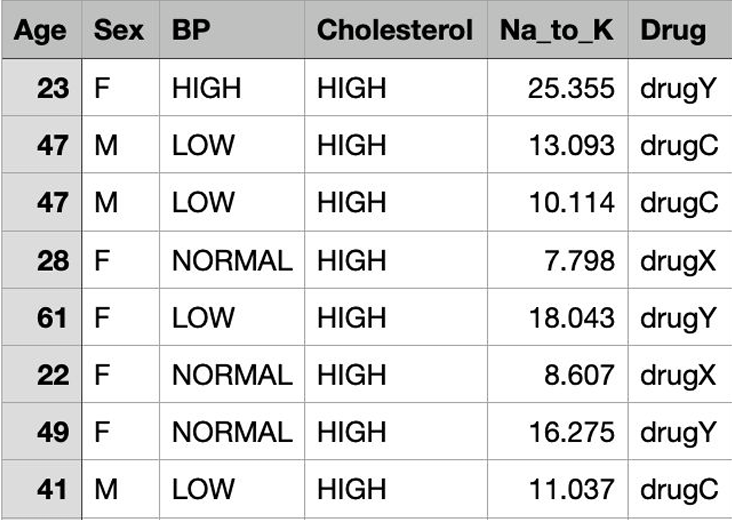

In [1]:
from IPython.display import Image, display

display(Image(filename='/home/javi/Imágenes/variables.png'))

Paso a paso:

Cargar la base de datos “drugs.csv” en Python e investigar cómo convertir las variables predictoras cualitativas de esta base a una escala numérica mediante la instrucción “preprocessing.LabelEncoder()”. Por ejemplo, si una variable tiene 3 posibles categorías, deberá cambiar sus resultados a 0, 1 o 2.

Usar los diversos métodos de optimización para una Regresión Logística vistos para encontrar un algoritmo óptimo de clasificación. Explicar cuál sería su recomendación para este caso. Regresión Logística 

¿Qué tan eficaz es el algoritmo predictivo escogido? Explicar a detalle comentando sobre los indicadores obtenidos mediante el reporte de clasificación correspondiente y la curva ROC.

3. Importación de librerías.

In [2]:
# Manipulación de datos.
import pandas as pd
import numpy as np

# Visualización.
import matplotlib.pyplot as plt

# Codificación de variables categóricas.
from sklearn.preprocessing import LabelEncoder

# Evalúa sistemáticamente múltiples combinaciones de hiperparámetros para un modelo.
from sklearn.model_selection import GridSearchCV
# Función que permite encadenar múltiples pasos de preprocesamiento y modelos en un solo bloque.
from sklearn.pipeline import Pipeline
# Transforma datos numéricos para que tengan una media de cero (0) y una desviación estándar de uno (1).
from sklearn.preprocessing import StandardScaler
# Permite predecir categorías basándose en un conjunto de datos.
from sklearn.linear_model import LogisticRegression
# Train_test_split: Divide tu conjunto de datos original en dos partes aleatorias: una para entrenar 
# el modelo y otra para probarlo.
# StratifiedKFold: Divide los datos en k partes iguales. Asegura que cada parte mantenga la
# misma proporción de clases que el conjunto original.
from sklearn.model_selection import (train_test_split, StratifiedKFold)

# Importa las herramientas necesarias para evaluar qué tan bien clasifica el modelo KNN.
# accuracy_score calcula que tanto acierta el modelo.¿Cuántas acertó?
# precision_score calcula la precision de las predicciones positivas.
# recall_score sensibilidad del modelo.
# f1_score combinacion de precision y recall.¿Hay un buen equilibrio entre precisión y detección?"
# confusion_matrix construye la matriz de confusion.
# roc_curve genera los datos necesarios para la curva ROC que muestra como cambia el rendimiento del modelo al modificar el umbral.
# roc_auc_score calcula el Área Bajo la Curva (AUC).
# classification_report genera automáticamente un resumen con varias métricas.
# RocCurveDisplay herramienta de visualización de alto nivel diseñada para graficar la Curva ROC. 
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, roc_auc_score, RocCurveDisplay, classification_report)

In [3]:
#Verificación que todas las librerias quedaron instaladas y su version.
import pandas
import numpy
import sklearn
import matplotlib

print("Pandas:", pd.__version__)
print("NumPy:", numpy.__version__)
print("Scikit-Learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

Pandas: 2.3.3
NumPy: 2.3.5
Scikit-Learn: 1.7.2
Matplotlib: 3.10.6


4. Carga del conjunto de datos.

In [4]:
# Se carga el archivo
df = pd.read_csv("drugs.csv")

5. Análisis exploratorio de los datos.

In [5]:
# Se visualiza archivo. 
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [6]:
# Dimensiones del conjunto de datos.
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

Filas: 200
Columnas: 6


In [7]:
# Nos muestra valores.
df.describe()

,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


In [8]:
# Valores nulos por variable.
df.isnull().sum()

Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64

In [9]:
# Información general del dataset.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


In [10]:
# Se verifica que no tengamos datos duplicados.
df.duplicated().sum()

np.int64(0)

6. Preparación de datos.

Los algoritmos de Machine Learning trabajan mediante operaciones matemáticas. Por ello, las variables categóricas deben transformarse a una representación numérica antes del entrenamiento del modelo.

In [11]:
# Carga de archivo
df = pd.read_csv("drugs.csv")

In [12]:
# Se crea una nueva variable diferenciando proveedor Nacional y Extranjero.
df["Provider"] = df["Drug"].map({"drugA": "Nacional","drugB": "Nacional",
    "drugC": "Nacional", "drugX": "Extranjero", "drugY": "Extranjero"})

# Codificación de variables.
le_sex = LabelEncoder()
le_bp = LabelEncoder()
le_chol = LabelEncoder()
le_provider = LabelEncoder()

df["Sex"] = le_sex.fit_transform(df["Sex"])
df["BP"] = le_bp.fit_transform(df["BP"])
df["Cholesterol"] = le_chol.fit_transform(df["Cholesterol"])
df["Provider"] = le_provider.fit_transform(df["Provider"])

print("Sex:", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print("BP:", dict(zip(le_bp.classes_, le_bp.transform(le_bp.classes_))))
print("Cholesterol:", dict(zip(le_chol.classes_, le_chol.transform(le_chol.classes_))))
print(dict(zip(le_provider.classes_,le_provider.transform(le_provider.classes_))))

Sex: {'F': np.int64(0), 'M': np.int64(1)}
BP: {'HIGH': np.int64(0), 'LOW': np.int64(1), 'NORMAL': np.int64(2)}
Cholesterol: {'HIGH': np.int64(0), 'NORMAL': np.int64(1)}
{'Extranjero': np.int64(0), 'Nacional': np.int64(1)}


Las variables categóricas fueron transformadas a valores numéricos mediante LabelEncoder, permitiendo que el modelo de Regresión Logística pueda procesarlas. La correspondencia entre categorías y valores se conserva para interpretar correctamente las regresiones del modelo.

7. Construcción del modelo Regresión Logística.

Recordemos que nos piden métodos, es decir, son varios modelos de optimización para una Regresión Logística con distintos solvers que debemos identificar correctamente y compararlos.

In [13]:
# Se separan variables.

# Variables predictoras.
X = df[["Age", "Sex", "BP", "Cholesterol", "Na_to_K"]]

# Variable objetivo.
y = df["Provider"]

In [14]:
# División del conjunto de datos.
from sklearn.model_selection import train_test_split

# División del conjunto de datos en entrenamiento y prueba.
# test_size = 30% de los datos se guardan para prueba.
# random_state = 42 asegura que el resultado sea reproducible.
# stratify = y mantiene la misma proporción de las clases en los conjuntos de entrenamiento y prueba. 
# De esta forma, ambos representan adecuadamente la distribución original de la base de datos y se evita 
# que una división aleatoria genere muestras poco representativas, lo que podría afectar la evaluación de modelo.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30,
    random_state=42, stratify=y)

In [15]:
# Construcción del Pipeline.

# Se aplica esta secuencia para no olvidar el escalado o aplicarlo de forma incorrecta.
pipeline = Pipeline([("scaler", StandardScaler()),("logistic", LogisticRegression(random_state=42, max_iter=5000))])

Nota técnica: 

Un solver es el algoritmo numérico que utiliza la Regresión Logística para encontrar los coeficientes que mejor separan las clases.

Penalty es un tipo de regularización aplicado para controlar la complejidad del modelo.

C es la Intensidad de la regularización; valores pequeños implican mayor penalización.

In [16]:
# Comparamos métodos de optimización.
param_grid = [{"logistic__solver": ["liblinear"],
    "logistic__penalty": ["l1", "l2"],"logistic__C": [0.01, 0.1, 1, 10, 100]},
    {"logistic__solver": ["lbfgs", "newton-cg", "newton-cholesky", "sag"],
    "logistic__penalty": ["l2"],"logistic__C": [0.01, 0.1, 1, 10, 100]},
    {"logistic__solver": ["saga"],"logistic__penalty": ["l1", "l2"],
    "logistic__C": [0.01, 0.1, 1, 10, 100]}]

Se compararon distintos métodos de optimización (solver) junto con diferentes tipos de regularización (penalty) y valores del parámetro C. La selección del mejor modelo se realizó mediante validación cruzada, eligiendo la configuración que obtuvo el mejor desempeño según la métrica ROC-AUC.

In [17]:
# Se busca el mejor modelo.
grid = GridSearchCV(estimator=pipeline, param_grid=param_grid, scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), n_jobs=-1)

grid.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"[{'logistic__C': [0.01, 0.1, ...], 'logistic__penalty': ['l1', 'l2'], 'logistic__solver': ['liblinear']}, {'logistic__C': [0.01, 0.1, ...], 'logistic__penalty': ['l2'], 'logistic__solver': ['lbfgs', 'newton-cg', ...]}, ...]"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [18]:
# Verificación de parámetros del modelo que eligió el programa.
print("Mejores parámetros:")
print(grid.best_params_)

print()

print("Mejor ROC-AUC obtenido en validación:")
print(grid.best_score_)

Mejores parámetros:
{'logistic__C': 1, 'logistic__penalty': 'l1', 'logistic__solver': 'liblinear'}

Mejor ROC-AUC obtenido en validación:
0.99875


Nota técnica:

GridSearchCV evaluó automáticamente distintas combinaciones de métodos de optimización (solver), tipos de regularización (penalty) y valores del parámetro de regularización (C) mediante validación cruzada. La configuración seleccionada fue aquella que obtuvo el mayor valor de ROC-AUC, indicando la mejor capacidad para distinguir entre medicamentos de proveedor nacional y extranjero.

Mejores parámetros:
{'logistic__C': 1, 'logistic__penalty': 'l1', 'logistic__solver': 'liblinear'}

Mejor ROC-AUC obtenido en validación:
0.99875

In [19]:
# Toma el mejor Pipeline encontrado por GridSearchCV.
best_model = grid.best_estimator_

In [20]:
# Usa el modelo para generar la clasificación final de pacientes de cada caso del conjunto de prueba.
y_pred = best_model.predict(X_test)

In [21]:
# Probabilidades estimadas de pertenecer a la clase 1.
y_prob = best_model.predict_proba(X_test)[:,1]

Se recupera el mejor modelo encontrado, se utiliza para predecir la clase de los pacientes del conjunto de prueba y se comparan esas predicciones con los valores reales de y_test para evaluar si el rendimiento observado en validación se mantiene en datos no utilizados durante el entrenamiento.

In [22]:
# Se verifica como LabelEncoder etiqueto Nacional y Extranjero.
print(dict(zip(le_provider.classes_,le_provider.transform(le_provider.classes_))))

{'Extranjero': np.int64(0), 'Nacional': np.int64(1)}


Al etiquetar Nacional como 1, confirmamos que es clase positiva.

In [23]:
# Proporción total de predicciones correctas.
accuracy = accuracy_score(y_test, y_pred)

# Precisión de los casos clasificados como clase 1, cuántos eran realmente clase 1.
precision = precision_score(y_test, y_pred)

# De todos los casos reales de la clase 1, cuántos detectó el modelo.
recall = recall_score(y_test, y_pred)

# F1-score.
f1 = f1_score(y_test, y_pred)

# Capacidad del modelo para separar ambas clases considerando distintos umbrales.
roc_auc = roc_auc_score(y_test, y_prob)

# Impresión de resultados.
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Accuracy:  0.9667
Precision: 0.9375
Recall:    0.9375
F1-score:  0.9375
ROC-AUC:   0.9929


8. Evaluación.

Interpretación del modelo:

El modelo obtuvo un Accuracy del 96.67 %, lo que indica una elevada proporción de clasificaciones correctas sobre el conjunto de prueba. Además, los valores de Precision, Recall y F1-score fueron de 0.9375, reflejando un buen equilibrio entre la capacidad para identificar correctamente la clase positiva (Nacional) y la precisión de sus predicciones. Finalmente, el ROC-AUC de 0.9929 confirma una capacidad excelente para discriminar entre medicamentos de proveedor nacional y extranjero, manteniendo un rendimiento muy similar al observado durante la validación cruzada.

In [24]:
# Se ejecuta la matriz de confusión para su análisis.
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[43  1]
 [ 1 15]]


In [25]:
# Se construye tabla comparativa.
cm_df = pd.DataFrame(cm,index=["Real: Extranjero", "Real: Nacional"], 
                     columns=["Pred.: Extranjero", "Pred.: Nacional"])

cm_df

,Pred.: Extranjero,Pred.: Nacional
Real: Extranjero,43,1
Real: Nacional,1,15


La matriz de confusión muestra que el modelo clasificó correctamente 58 de los 60 pacientes del conjunto de prueba. En particular, identificó correctamente 43 pacientes correspondientes a medicamentos de proveedor extranjero y 15 pacientes asociados a medicamentos de proveedor nacional. Únicamente se registró un falso positivo y un falso negativo, lo que indica que los errores fueron escasos y se distribuyeron de forma equilibrada entre ambas clases. Este comportamiento es consistente con los elevados valores obtenidos en Accuracy, Precision, Recall, F1-score y ROC-AUC.



9. Interpretación.

In [26]:
# Se presenta reporte de metricas.
reporte_df = pd.DataFrame(classification_report(y_test, y_pred,
        target_names=["Extranjero", "Nacional"], output_dict=True)).transpose()

reporte_df

,precision,recall,f1-score,support
Extranjero,0.977273,0.977273,0.977273,44.000000
Nacional,0.937500,0.937500,0.937500,16.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.957386,0.957386,0.957386,60.000000
weighted avg,0.966667,0.966667,0.966667,60.000000


Podemos observar que el modelo identifica los medicamentos de proveedor extranjero con una gran precisión, clasificando correctamente 43 de los 44 casos evaluados, lo que representa un 97.73 % de acierto. Por otro lado, para los medicamentos de proveedor nacional, el modelo clasificó correctamente 15 de los 16 casos, alcanzando un 93.75 % de acierto.

Aunque existe una diferencia de aproximadamente 4 puntos porcentuales entre ambas clases, esta es reducida y no evidencia un sesgo significativo a favor de alguna de ellas. Esta conclusión se ve reforzada por la matriz de confusión, donde se observa únicamente un falso positivo y un falso negativo, indicando que los errores se distribuyen de forma equilibrada entre ambas categorías.

Este resultado constituye un ejemplo claro de cómo la matriz de confusión y las métricas de evaluación se complementan: mientras la matriz permite identificar dónde se producen los errores, las métricas cuantifican el impacto de dichos errores sobre el rendimiento del modelo.

10. Creación de Curva ROC.

In [27]:
# Se calculan las probabilidades de la clase positiva.
y_prob = best_model.predict_proba(X_test)[:, 1]

# Obtenemos la curva.
# frp (False Positive Rate) "Probabilidad de falso positivo."
# trp (True Positive Rate) "Probabilidad de verdadero positivo."
# threshold Los distintos niveles de probabilidad que el modelo utiliza para decidir 
# cuando una observación pasa de "permanece" a "abandona".
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# El AUC resume el comportamiento global del modelo considerando todos los posibles umbrales de decisión.
# Permite evaluar la capacidad del modelo para distinguir entre ambas clases y proporciona información
# para que la organización seleccione el umbral de decisión más adecuado según las necesidades del negocio.
auc = roc_auc_score(y_test, y_prob)

print(f"ROC-AUC: {auc:.4f}")

ROC-AUC: 0.9929


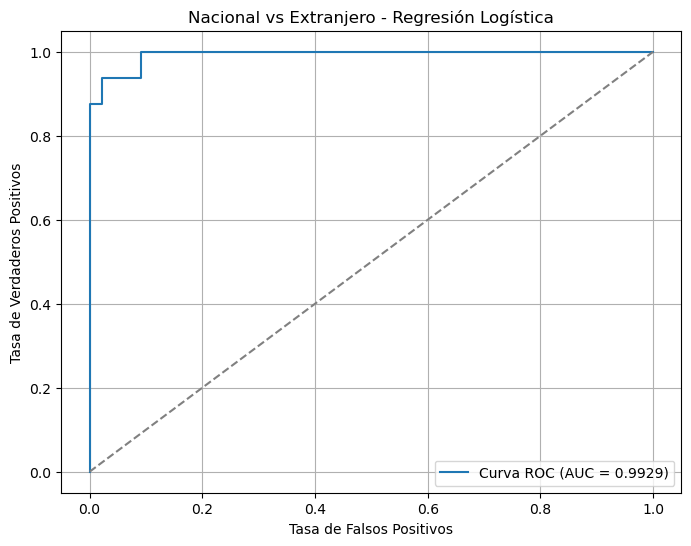

In [28]:
# Se dimensiona grafico.
plt.figure(figsize=(8,6))

# Se grafica la curva ROC utilizando la tasa de falsos positivos (FPR)
# y la tasa de verdaderos positivos (TPR).
# Esta visualización permite observar el equilibrio entre detectar correctamente
# los casos positivos y generar falsas alarmas.
# label asigna un nombre descriptivo a la línea representada en la gráfica,
# facilitando su identificación e interpretación por parte del lector.
# La f permite construir mensajes dinámicos utilizando el valor actual de las variables.
# roc_auc Inserta el valor actual de la variable dentro del texto que se mostrará en la gráfica.
# 3f incluye el valor AUC redondeado a tres decimales.(Mostrar tres decimales proporciona la precisión 
# necesaria sin distraer al lector con un nivel de detalle que no aporta valor a la decisión).
plt.plot(fpr, tpr,label=f"Curva ROC (AUC = {auc:.4f})")

# Se establece una referencia común para comparar objetivamente el rendimiento del modelo.
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

# Se nombran ambos ejes para que el lector identifique rápidamente qué representa
# cada medida y pueda interpretar la gráfica sin generar confusiones.
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")

# Se incirpora un título que contextualiza la visualización,
# permitiendo identificar rápidamente el objetivo del análisis
# antes de interpretar el comportamiento del modelo.
plt.title("Nacional vs Extranjero - Regresión Logística")
plt.legend()

# Se añaden referencias visuales que permitan al lector concentrarse
# en interpretar la información sin perder tiempo estimando posiciones
# dentro de la gráfica.
plt.grid(True)

plt.show()

11. Conclusiones.

El primer aspecto que llama la atención es que la curva ROC alcanza rápidamente la zona superior izquierda de la gráfica, mostrando una elevada capacidad para discriminar entre las clases Proveedor Nacional y Proveedor Extranjero. Al mismo tiempo, la distancia respecto a la línea de referencia indica que el modelo presenta una elevada capacidad de discriminación.

Este comportamiento consigue una elevada tasa de verdaderos positivos manteniendo una baja tasa de falsos positivos.

El valor de AUC obtenido (0.9929) confirma que el modelo presenta un excelente desempeño para distinguir entre ambas clases, proporcionando una base sólida para apoyar la toma de decisiones.

Sin embargo, una buena capacidad predictiva no debe llevarnos a dar por finalizado el análisis. El siguiente paso consiste en preguntarnos si las variables disponibles describen adecuadamente el problema objeto de estudio o si sería conveniente incorporar información adicional que permita mejorar la capacidad predictiva del modelo.